
# Conversational Product Discovery — Adversarial MVP v2

This notebook stress-tests the project’s core architecture after MVP v1 succeeded.

## Registered scope reflected here

**Natural-language conversation → structured preference update → validated preference state → deterministic candidate retrieval → grounded response**

This notebook deliberately does **not** introduce embeddings, vector search, a learned recommender, or a GPU-dependent retrieval model. Candidate retrieval remains deterministic over structured catalogue fields.

## Main purpose of v2

MVP v1 showed that the happy path works. v2 tries to break the preference-state component with harder language:

- accumulation
- multi-attribute turns
- corrections / overwrites
- removals
- cross-turn references
- colloquial language
- unit conversion
- contradictory wording
- ambiguous requests
- unsupported requirements
- no-op / conversational turns
- longer state histories

The primary measurements are:

1. **Update Exact Match** — did the LLM produce the correct state delta for this turn?
2. **State Exact Match** — after deterministic merge, is the complete state correct?
3. **Active-field Accuracy** — field-level accuracy without inflating results using unused `None` fields.
4. **Clarification Accuracy** — did the system correctly decide when it should not safely update the state?
5. **Accuracy by dialogue depth and scenario type** — where do errors appear as conversations become harder?

> Recommended first run: `USE_OPENAI = False` to verify notebook logic.  
> Then switch to `USE_OPENAI = True` for the actual adversarial test.


In [1]:
!pip -q install -U openai pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 636.8 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 60.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 75.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.


In [2]:

import os
import json
import time
import copy
from getpass import getpass
from typing import Any, Dict, List, Optional, Tuple

import pandas as pd
import matplotlib.pyplot as plt

USE_OPENAI = True
MODEL = "gpt-5.6-terra"

# Full benchmark = 20 dialogues / 80 turns.
# Set to 5 for a cheaper quick run.
MAX_DIALOGUES = 20

RUN_RESPONSE_GENERATION = True
MAX_RESPONSE_DEMOS = 5

if USE_OPENAI:
    if not os.environ.get("OPENAI_API_KEY"):
        os.environ["OPENAI_API_KEY"] = getpass("Enter OPENAI_API_KEY: ")
    from openai import OpenAI
    client = OpenAI()
else:
    client = None

print("USE_OPENAI =", USE_OPENAI)
print("MODEL =", MODEL)
print("MAX_DIALOGUES =", MAX_DIALOGUES)


Enter OPENAI_API_KEY: ··········
USE_OPENAI = True
MODEL = gpt-5.6-terra
MAX_DIALOGUES = 20



## 1. Canonical preference state

The language model does **not** own the session state. It proposes a delta for the latest user turn; deterministic application code validates and merges that delta.


In [3]:

SUPPORTED_FIELDS = {
    "budget_max": "Maximum budget in AUD.",
    "brand": "Preferred laptop brand.",
    "ram_min_gb": "Minimum RAM in GB.",
    "storage_min_gb": "Minimum storage in GB.",
    "screen_size_max_in": "Maximum screen size in inches.",
    "gpu_required": "Required GPU family/model.",
    "usage": "Canonical usage: study, gaming, creative, business, or general.",
}

EMPTY_STATE = {
    "budget_max": None,
    "brand": None,
    "ram_min_gb": None,
    "storage_min_gb": None,
    "screen_size_max_in": None,
    "gpu_required": None,
    "usage": None,
}

def new_state():
    return copy.deepcopy(EMPTY_STATE)

def pretty_state(state):
    return json.dumps(state, indent=2, ensure_ascii=False)

print(pretty_state(new_state()))


{
  "budget_max": null,
  "brand": null,
  "ram_min_gb": null,
  "storage_min_gb": null,
  "screen_size_max_in": null,
  "gpu_required": null,
  "usage": null
}



## 2. State-update contract

If a supported requirement is too vague to update safely, or if the user expresses an important requirement outside the current schema, the model should not invent a value. It should return no unsafe update and set `clarification_needed=true`.


In [4]:

UPDATE_JSON_SCHEMA = {
    "type": "object",
    "properties": {
        "updates": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "field": {"type": "string", "enum": list(SUPPORTED_FIELDS.keys())},
                    "operation": {"type": "string", "enum": ["set", "remove"]},
                    "value": {"type": ["string", "null"]}
                },
                "required": ["field", "operation", "value"],
                "additionalProperties": False
            }
        },
        "clarification_needed": {"type": "boolean"},
        "clarification_question": {"type": ["string", "null"]}
    },
    "required": ["updates", "clarification_needed", "clarification_question"],
    "additionalProperties": False
}

EXTRACTION_INSTRUCTIONS = """
You are the natural-language preference-update extractor for a laptop product-discovery system.

You receive:
- the supported schema,
- the current validated preference state,
- the latest user message.

Your job is ONLY to extract state changes supported by the latest user message.

Rules:
1. Return only fields changed by the latest message. Do not repeat unchanged state.
2. Use operation="set" for a new or revised requirement.
3. Use operation="remove" only when the user explicitly revokes an existing requirement.
4. Never invent a value that is not supported by the user's language.
5. Use CURRENT VALIDATED STATE only to resolve contextual references such as "make that 32", "double that storage", or "forget the brand".
6. If the user states two values for the same field in one turn and clearly corrects themselves, keep only the final intended value.
7. Normalize explicit monetary values:
   - "1.5 grand" -> "1500"
8. Normalize RAM/storage:
   - 1 TB -> 1024 GB
   - 2 TB -> 2048 GB
9. Normalize usage to one of: study, gaming, creative, business, general.
10. For "14 inches or smaller" or equivalent, set screen_size_max_in=14.
11. If a supported requirement is too vague to map safely (e.g. "not too expensive"), return no guessed value for that field and set clarification_needed=true.
12. If the user expresses an important requirement that the current schema cannot represent (e.g. battery life or excluding a brand), do not force it into another field. Set clarification_needed=true.
13. Pure conversational/no-op turns such as "thanks" should normally return no updates and clarification_needed=false.
14. Do not interpret sentiment, politeness, or explanation text as a new product constraint.
"""


## 3. Deterministic validation and state management

In [5]:

def _parse_value(field, value):
    if value is None:
        raise ValueError(f"{field}: set operation requires a value")

    if field == "budget_max":
        x = float(value)
        if not (0 < x <= 100000):
            raise ValueError("budget_max out of range")
        return x

    if field == "ram_min_gb":
        x = int(float(value))
        if not (1 <= x <= 512):
            raise ValueError("ram_min_gb out of range")
        return x

    if field == "storage_min_gb":
        x = int(float(value))
        if not (1 <= x <= 32768):
            raise ValueError("storage_min_gb out of range")
        return x

    if field == "screen_size_max_in":
        x = float(value)
        if not (8 <= x <= 25):
            raise ValueError("screen_size_max_in out of range")
        return x

    if field == "usage":
        x = value.strip().lower()
        allowed = {"study", "gaming", "creative", "business", "general"}
        if x not in allowed:
            raise ValueError(f"usage must be one of {sorted(allowed)}")
        return x

    if field == "brand":
        x = value.strip()
        if not x:
            raise ValueError("brand cannot be blank")
        return x

    if field == "gpu_required":
        x = value.strip().upper()
        if not x:
            raise ValueError("gpu_required cannot be blank")
        return x

    raise ValueError(f"Unsupported field: {field}")


def apply_update(current_state, update_payload):
    state = copy.deepcopy(current_state)
    audit = []

    for item in update_payload["updates"]:
        field = item["field"]
        operation = item["operation"]
        raw_value = item["value"]

        if field not in SUPPORTED_FIELDS:
            audit.append({"field": field, "status": "rejected", "reason": "unsupported field"})
            continue

        try:
            if operation == "remove":
                old = state[field]
                state[field] = None
                audit.append({"field": field, "operation": "remove", "old": old, "new": None, "status": "accepted"})

            elif operation == "set":
                parsed = _parse_value(field, raw_value)
                old = state[field]
                state[field] = parsed
                audit.append({"field": field, "operation": "set", "old": old, "new": parsed, "status": "accepted"})

            else:
                raise ValueError(f"Unsupported operation: {operation}")

        except Exception as e:
            audit.append({
                "field": field,
                "operation": operation,
                "value": raw_value,
                "status": "rejected",
                "reason": str(e)
            })

    return state, audit


## 4. LLM adapter

In [6]:

def build_extraction_input(current_state, user_message):
    return f"""
SUPPORTED SCHEMA:
{json.dumps(SUPPORTED_FIELDS, indent=2)}

CURRENT VALIDATED STATE:
{json.dumps(current_state, indent=2)}

LATEST USER MESSAGE:
{user_message}
""".strip()


def extract_update_openai(current_state, user_message):
    start = time.perf_counter()

    response = client.responses.create(
        model=MODEL,
        instructions=EXTRACTION_INSTRUCTIONS,
        input=build_extraction_input(current_state, user_message),
        text={
            "format": {
                "type": "json_schema",
                "name": "preference_update",
                "schema": UPDATE_JSON_SCHEMA,
                "strict": True
            }
        }
    )

    latency_s = time.perf_counter() - start
    payload = json.loads(response.output_text)

    usage = getattr(response, "usage", None)
    input_tokens = getattr(usage, "input_tokens", None) if usage else None
    output_tokens = getattr(usage, "output_tokens", None) if usage else None

    return payload, {
        "latency_s": latency_s,
        "input_tokens": input_tokens,
        "output_tokens": output_tokens,
    }


def extract_update(current_state, user_message, oracle_update=None):
    if USE_OPENAI:
        return extract_update_openai(current_state, user_message)

    if oracle_update is None:
        raise ValueError("Mock mode requires oracle_update.")

    return copy.deepcopy(oracle_update), {
        "latency_s": 0.0,
        "input_tokens": 0,
        "output_tokens": 0,
    }



## 5. Ground-truth helpers

The benchmark defines semantic state updates first. Oracle full states are then computed deterministically before the model is evaluated.


In [7]:

def set_update(field, value):
    return {"field": field, "operation": "set", "value": str(value)}

def remove_update(field):
    return {"field": field, "operation": "remove", "value": None}

def oracle_payload(*updates, clarify=False, question=None):
    return {
        "updates": list(updates),
        "clarification_needed": clarify,
        "clarification_question": question if clarify else None
    }

def compile_oracle_states(dialogues):
    compiled = copy.deepcopy(dialogues)

    for dialogue in compiled:
        state = new_state()

        for turn in dialogue["turns"]:
            state, audit = apply_update(state, turn["oracle_update"])
            rejected = [x for x in audit if x["status"] == "rejected"]
            if rejected:
                raise ValueError(f"Invalid oracle update in {dialogue['name']}: {rejected}")
            turn["expected_state"] = copy.deepcopy(state)

    return compiled


## 6. Twenty manually authored adversarial dialogues (80 turns)

In [8]:

RAW_DIALOGUES = [
    {
        "name": "D01 — accumulation and explicit correction",
        "turns": [
            {"type":"simple_set", "message":"I need a laptop for uni.", "oracle_update":oracle_payload(set_update("usage","study"))},
            {"type":"multi_attribute", "message":"Keep it below $1,500 and give me at least 16 gigs of RAM.", "oracle_update":oracle_payload(set_update("budget_max","1500"), set_update("ram_min_gb","16"))},
            {"type":"unit_expression", "message":"Half a terabyte of storage minimum.", "oracle_update":oracle_payload(set_update("storage_min_gb","512"))},
            {"type":"correction", "message":"Actually, scratch the 16 GB — make that 32.", "oracle_update":oracle_payload(set_update("ram_min_gb","32"))},
        ]
    },
    {
        "name": "D02 — removal with retained context",
        "turns": [
            {"type":"multi_attribute", "message":"Dell, business use, and no more than two grand.", "oracle_update":oracle_payload(set_update("brand","Dell"), set_update("usage","business"), set_update("budget_max","2000"))},
            {"type":"unit_conversion", "message":"At least one terabyte of storage.", "oracle_update":oracle_payload(set_update("storage_min_gb","1024"))},
            {"type":"removal", "message":"Forget the Dell requirement; brand isn't important now.", "oracle_update":oracle_payload(remove_update("brand"))},
            {"type":"cross_turn_retention", "message":"But keep everything else, and make it 14 inches or smaller.", "oracle_update":oracle_payload(set_update("screen_size_max_in","14"))},
        ]
    },
    {
        "name": "D03 — gaming and budget overwrite",
        "turns": [
            {"type":"multi_attribute", "message":"Gaming machine, RTX 4060 please.", "oracle_update":oracle_payload(set_update("usage","gaming"), set_update("gpu_required","RTX 4060"))},
            {"type":"colloquial_numeric", "message":"I can stretch to 2.4 grand.", "oracle_update":oracle_payload(set_update("budget_max","2400"))},
            {"type":"multi_attribute", "message":"16 GB RAM minimum, one TB storage.", "oracle_update":oracle_payload(set_update("ram_min_gb","16"), set_update("storage_min_gb","1024"))},
            {"type":"correction", "message":"Actually that's too much. Cap it at $2,000 instead.", "oracle_update":oracle_payload(set_update("budget_max","2000"))},
        ]
    },
    {
        "name": "D04 — colloquial money and memory",
        "turns": [
            {"type":"colloquial_numeric", "message":"Something for study, fifteen hundred bucks tops.", "oracle_update":oracle_payload(set_update("usage","study"), set_update("budget_max","1500"))},
            {"type":"colloquial_numeric", "message":"I'd like thirty-two gigs of memory.", "oracle_update":oracle_payload(set_update("ram_min_gb","32"))},
            {"type":"no_op", "message":"Yep, that sounds about right.", "oracle_update":oracle_payload()},
            {"type":"unit_conversion", "message":"Oh, and at least 1 TB storage.", "oracle_update":oracle_payload(set_update("storage_min_gb","1024"))},
        ]
    },
    {
        "name": "D05 — storage conversion and doubling reference",
        "turns": [
            {"type":"simple_set", "message":"Business laptop.", "oracle_update":oracle_payload(set_update("usage","business"))},
            {"type":"unit_conversion", "message":"One terabyte storage minimum.", "oracle_update":oracle_payload(set_update("storage_min_gb","1024"))},
            {"type":"cross_turn_reference", "message":"Actually double that storage requirement.", "oracle_update":oracle_payload(set_update("storage_min_gb","2048"))},
            {"type":"simple_set", "message":"Keep it under $2,500.", "oracle_update":oracle_payload(set_update("budget_max","2500"))},
        ]
    },
    {
        "name": "D06 — dense multi-attribute turn",
        "turns": [
            {"type":"multi_attribute", "message":"For university: Lenovo, under $1,800, at least 16 GB RAM and 1 TB storage.", "oracle_update":oracle_payload(set_update("usage","study"), set_update("brand","Lenovo"), set_update("budget_max","1800"), set_update("ram_min_gb","16"), set_update("storage_min_gb","1024"))},
            {"type":"simple_set", "message":"14 inches or smaller.", "oracle_update":oracle_payload(set_update("screen_size_max_in","14"))},
            {"type":"removal", "message":"Brand can be anything after all.", "oracle_update":oracle_payload(remove_update("brand"))},
            {"type":"correction", "message":"But raise the RAM minimum to 32 GB.", "oracle_update":oracle_payload(set_update("ram_min_gb","32"))},
        ]
    },
    {
        "name": "D07 — elliptical correction",
        "turns": [
            {"type":"simple_set", "message":"At least 16 GB RAM.", "oracle_update":oracle_payload(set_update("ram_min_gb","16"))},
            {"type":"cross_turn_reference", "message":"Make that 32 instead.", "oracle_update":oracle_payload(set_update("ram_min_gb","32"))},
            {"type":"simple_set", "message":"Budget ceiling is $1,900.", "oracle_update":oracle_payload(set_update("budget_max","1900"))},
            {"type":"no_op", "message":"Cool, leave the rest as is.", "oracle_update":oracle_payload()},
        ]
    },
    {
        "name": "D08 — informal removal",
        "turns": [
            {"type":"multi_attribute", "message":"ASUS for gaming, max $2,200.", "oracle_update":oracle_payload(set_update("brand","ASUS"), set_update("usage","gaming"), set_update("budget_max","2200"))},
            {"type":"simple_set", "message":"RTX 4060.", "oracle_update":oracle_payload(set_update("gpu_required","RTX 4060"))},
            {"type":"removal", "message":"Actually forget the brand thing.", "oracle_update":oracle_payload(remove_update("brand"))},
            {"type":"simple_set", "message":"At least 16 GB RAM.", "oracle_update":oracle_payload(set_update("ram_min_gb","16"))},
        ]
    },
    {
        "name": "D09 — no-op conversational turns",
        "turns": [
            {"type":"simple_set", "message":"I need a general-purpose laptop under $1,600.", "oracle_update":oracle_payload(set_update("usage","general"), set_update("budget_max","1600"))},
            {"type":"no_op", "message":"Thanks, that's helpful.", "oracle_update":oracle_payload()},
            {"type":"no_op", "message":"Let me think for a second.", "oracle_update":oracle_payload()},
            {"type":"simple_set", "message":"Okay, 16 GB RAM minimum.", "oracle_update":oracle_payload(set_update("ram_min_gb","16"))},
        ]
    },
    {
        "name": "D10 — ambiguous budget then resolution",
        "turns": [
            {"type":"simple_set", "message":"I need a laptop for study.", "oracle_update":oracle_payload(set_update("usage","study"))},
            {"type":"ambiguity", "message":"I don't want it to be too expensive.", "oracle_update":oracle_payload(clarify=True, question="Please provide a maximum budget in AUD.")},
            {"type":"ambiguity_resolution", "message":"Let's say no more than $1,700.", "oracle_update":oracle_payload(set_update("budget_max","1700"))},
            {"type":"simple_set", "message":"And at least 16 GB RAM.", "oracle_update":oracle_payload(set_update("ram_min_gb","16"))},
        ]
    },
    {
        "name": "D11 — unsupported battery requirement",
        "turns": [
            {"type":"simple_set", "message":"Business laptop under $2,000.", "oracle_update":oracle_payload(set_update("usage","business"), set_update("budget_max","2000"))},
            {"type":"unsupported_schema", "message":"Battery life is really important — I want at least 12 hours.", "oracle_update":oracle_payload(clarify=True, question="Battery life is not represented in the current MVP schema.")},
            {"type":"simple_set", "message":"Okay, then just make RAM at least 16 GB.", "oracle_update":oracle_payload(set_update("ram_min_gb","16"))},
            {"type":"simple_set", "message":"And storage at least 512 GB.", "oracle_update":oracle_payload(set_update("storage_min_gb","512"))},
        ]
    },
    {
        "name": "D12 — self-correction inside one message",
        "turns": [
            {"type":"simple_set", "message":"Gaming laptop.", "oracle_update":oracle_payload(set_update("usage","gaming"))},
            {"type":"contradictory_same_turn", "message":"Budget under $1,800 — actually, make that $1,600.", "oracle_update":oracle_payload(set_update("budget_max","1600"))},
            {"type":"contradictory_same_turn", "message":"16 GB RAM... no, 32 GB minimum.", "oracle_update":oracle_payload(set_update("ram_min_gb","32"))},
            {"type":"simple_set", "message":"RTX 4060.", "oracle_update":oracle_payload(set_update("gpu_required","RTX 4060"))},
        ]
    },
    {
        "name": "D13 — brand swap in natural speech",
        "turns": [
            {"type":"simple_set", "message":"I'd prefer Dell.", "oracle_update":oracle_payload(set_update("brand","Dell"))},
            {"type":"correction", "message":"Actually not Dell — Lenovo instead.", "oracle_update":oracle_payload(set_update("brand","Lenovo"))},
            {"type":"simple_set", "message":"Under $2,000.", "oracle_update":oracle_payload(set_update("budget_max","2000"))},
            {"type":"simple_set", "message":"Mostly for work.", "oracle_update":oracle_payload(set_update("usage","business"))},
        ]
    },
    {
        "name": "D14 — shorthand and 1.5 grand",
        "turns": [
            {"type":"colloquial_numeric", "message":"Uni laptop, 1.5 grand max.", "oracle_update":oracle_payload(set_update("usage","study"), set_update("budget_max","1500"))},
            {"type":"colloquial_numeric", "message":"16 gigs minimum.", "oracle_update":oracle_payload(set_update("ram_min_gb","16"))},
            {"type":"unit_conversion", "message":"1 TB or more.", "oracle_update":oracle_payload(set_update("storage_min_gb","1024"))},
            {"type":"simple_set", "message":"Prefer something no bigger than 14 inches.", "oracle_update":oracle_payload(set_update("screen_size_max_in","14"))},
        ]
    },
    {
        "name": "D15 — cross-turn storage reference",
        "turns": [
            {"type":"simple_set", "message":"Acer is fine.", "oracle_update":oracle_payload(set_update("brand","Acer"))},
            {"type":"unit_conversion", "message":"At least a terabyte of storage.", "oracle_update":oracle_payload(set_update("storage_min_gb","1024"))},
            {"type":"cross_turn_reference", "message":"Can we double that?", "oracle_update":oracle_payload(set_update("storage_min_gb","2048"))},
            {"type":"simple_set", "message":"Keep the price under $2,300.", "oracle_update":oracle_payload(set_update("budget_max","2300"))},
        ]
    },
    {
        "name": "D16 — usage overwrite",
        "turns": [
            {"type":"simple_set", "message":"This is mainly for office work.", "oracle_update":oracle_payload(set_update("usage","business"))},
            {"type":"simple_set", "message":"At least 16 GB RAM.", "oracle_update":oracle_payload(set_update("ram_min_gb","16"))},
            {"type":"correction", "message":"Actually it'll mostly be for university, not work.", "oracle_update":oracle_payload(set_update("usage","study"))},
            {"type":"simple_set", "message":"Maximum budget $1,700.", "oracle_update":oracle_payload(set_update("budget_max","1700"))},
        ]
    },
    {
        "name": "D17 — preserve budget while changing memory",
        "turns": [
            {"type":"simple_set", "message":"Budget max $1,800.", "oracle_update":oracle_payload(set_update("budget_max","1800"))},
            {"type":"simple_set", "message":"16 GB RAM minimum.", "oracle_update":oracle_payload(set_update("ram_min_gb","16"))},
            {"type":"cross_turn_retention", "message":"Same budget, but bump the memory to 32 GB.", "oracle_update":oracle_payload(set_update("ram_min_gb","32"))},
            {"type":"no_op", "message":"Everything else can stay open.", "oracle_update":oracle_payload()},
        ]
    },
    {
        "name": "D18 — explicit removal of budget",
        "turns": [
            {"type":"multi_attribute", "message":"Creative work, under $2,500.", "oracle_update":oracle_payload(set_update("usage","creative"), set_update("budget_max","2500"))},
            {"type":"simple_set", "message":"32 GB RAM please.", "oracle_update":oracle_payload(set_update("ram_min_gb","32"))},
            {"type":"removal", "message":"Price doesn't matter anymore; remove the budget limit.", "oracle_update":oracle_payload(remove_update("budget_max"))},
            {"type":"simple_set", "message":"At least 1 TB storage.", "oracle_update":oracle_payload(set_update("storage_min_gb","1024"))},
        ]
    },
    {
        "name": "D19 — unsupported negative brand constraint",
        "turns": [
            {"type":"simple_set", "message":"I need a general laptop under $1,800.", "oracle_update":oracle_payload(set_update("usage","general"), set_update("budget_max","1800"))},
            {"type":"unsupported_schema", "message":"Anything except HP.", "oracle_update":oracle_payload(clarify=True, question="Brand exclusion is not represented in the current MVP schema.")},
            {"type":"ambiguity_resolution", "message":"Fine, let's just prefer Lenovo.", "oracle_update":oracle_payload(set_update("brand","Lenovo"))},
            {"type":"simple_set", "message":"16 GB RAM minimum.", "oracle_update":oracle_payload(set_update("ram_min_gb","16"))},
        ]
    },
    {
        "name": "D20 — highly elliptical memory correction",
        "turns": [
            {"type":"simple_set", "message":"For study, under $2,000.", "oracle_update":oracle_payload(set_update("usage","study"), set_update("budget_max","2000"))},
            {"type":"simple_set", "message":"RAM: 16 GB minimum.", "oracle_update":oracle_payload(set_update("ram_min_gb","16"))},
            {"type":"cross_turn_reference", "message":"Make it 32 instead.", "oracle_update":oracle_payload(set_update("ram_min_gb","32"))},
            {"type":"unit_conversion", "message":"Storage can be 1 TB minimum.", "oracle_update":oracle_payload(set_update("storage_min_gb","1024"))},
        ]
    },
]

DIALOGUES = compile_oracle_states(RAW_DIALOGUES)
print("Dialogues:", len(DIALOGUES))
print("Turns:", sum(len(d["turns"]) for d in DIALOGUES))


Dialogues: 20
Turns: 80



## 7. Small deterministic catalogue

This is only for system smoke-testing. The formal project can later replace it with the cleaned Amazon laptop catalogue.


In [9]:

mvp_catalogue = pd.DataFrame([
    {"product_id":"L01","title":"Dell Inspiron 14 Plus","brand":"Dell","price":1399,"ram_gb":32,"storage_gb":1024,"screen_in":14.0,"gpu":"INTEL ARC","usage_tags":["study","business","general"]},
    {"product_id":"L02","title":"Lenovo IdeaPad Pro 14","brand":"Lenovo","price":1499,"ram_gb":32,"storage_gb":1024,"screen_in":14.0,"gpu":"INTEGRATED","usage_tags":["study","business","general"]},
    {"product_id":"L03","title":"ASUS Zenbook 14","brand":"ASUS","price":1599,"ram_gb":16,"storage_gb":1024,"screen_in":14.0,"gpu":"INTEGRATED","usage_tags":["study","business","general"]},
    {"product_id":"L04","title":"HP Pavilion 14","brand":"HP","price":1199,"ram_gb":16,"storage_gb":512,"screen_in":14.0,"gpu":"INTEGRATED","usage_tags":["study","general"]},
    {"product_id":"L05","title":"Acer Swift Go 14","brand":"Acer","price":1299,"ram_gb":16,"storage_gb":1024,"screen_in":14.0,"gpu":"INTEGRATED","usage_tags":["study","business","general"]},
    {"product_id":"L06","title":"Dell Latitude 14","brand":"Dell","price":1899,"ram_gb":32,"storage_gb":1024,"screen_in":14.0,"gpu":"INTEGRATED","usage_tags":["business"]},
    {"product_id":"L07","title":"Lenovo ThinkPad T14","brand":"Lenovo","price":1999,"ram_gb":32,"storage_gb":1024,"screen_in":14.0,"gpu":"INTEGRATED","usage_tags":["business"]},
    {"product_id":"L08","title":"ASUS TUF Gaming A15","brand":"ASUS","price":1899,"ram_gb":16,"storage_gb":1024,"screen_in":15.6,"gpu":"RTX 4060","usage_tags":["gaming"]},
    {"product_id":"L09","title":"MSI Katana 15","brand":"MSI","price":2099,"ram_gb":16,"storage_gb":1024,"screen_in":15.6,"gpu":"RTX 4060","usage_tags":["gaming"]},
    {"product_id":"L10","title":"Lenovo Legion 5","brand":"Lenovo","price":2299,"ram_gb":32,"storage_gb":1024,"screen_in":16.0,"gpu":"RTX 4060","usage_tags":["gaming","creative"]},
    {"product_id":"L11","title":"ASUS ROG Zephyrus G14","brand":"ASUS","price":2399,"ram_gb":32,"storage_gb":1024,"screen_in":14.0,"gpu":"RTX 4060","usage_tags":["gaming","creative"]},
    {"product_id":"L12","title":"Acer Nitro V 15","brand":"Acer","price":1799,"ram_gb":16,"storage_gb":1024,"screen_in":15.6,"gpu":"RTX 4060","usage_tags":["gaming"]},
    {"product_id":"L13","title":"HP Envy 16 Creator","brand":"HP","price":2199,"ram_gb":32,"storage_gb":2048,"screen_in":16.0,"gpu":"RTX 4050","usage_tags":["creative","business"]},
    {"product_id":"L14","title":"Dell XPS 14","brand":"Dell","price":2499,"ram_gb":32,"storage_gb":1024,"screen_in":14.5,"gpu":"RTX 4050","usage_tags":["creative","business"]},
    {"product_id":"L15","title":"Lenovo Creator 14","brand":"Lenovo","price":2099,"ram_gb":32,"storage_gb":2048,"screen_in":14.0,"gpu":"RTX 4050","usage_tags":["creative","business"]},
    {"product_id":"L16","title":"Acer TravelMate 14","brand":"Acer","price":1699,"ram_gb":32,"storage_gb":1024,"screen_in":14.0,"gpu":"INTEGRATED","usage_tags":["business","general"]},
    {"product_id":"L17","title":"Lenovo Yoga 14","brand":"Lenovo","price":1699,"ram_gb":16,"storage_gb":1024,"screen_in":14.0,"gpu":"INTEGRATED","usage_tags":["study","general"]},
    {"product_id":"L18","title":"Dell G15","brand":"Dell","price":1999,"ram_gb":16,"storage_gb":1024,"screen_in":15.6,"gpu":"RTX 4060","usage_tags":["gaming"]},
])

REQUIRED_CATALOGUE_COLUMNS = {
    "product_id", "title", "brand", "price", "ram_gb",
    "storage_gb", "screen_in", "gpu", "usage_tags"
}

missing = REQUIRED_CATALOGUE_COLUMNS - set(mvp_catalogue.columns)
if missing:
    raise ValueError(f"MVP catalogue is missing required columns: {sorted(missing)}")

print("Catalogue columns:", list(mvp_catalogue.columns))
print("Catalogue rows:", len(mvp_catalogue))
display(mvp_catalogue)



Catalogue columns: ['product_id', 'title', 'brand', 'price', 'ram_gb', 'storage_gb', 'screen_in', 'gpu', 'usage_tags']
Catalogue rows: 18


,product_id,title,brand,price,ram_gb,storage_gb,screen_in,gpu,usage_tags
0,L01,Dell Inspiron 14 Plus,Dell,1399,32,1024,14.0,INTEL ARC,"[study, business, general]"
1,L02,Lenovo IdeaPad Pro 14,Lenovo,1499,32,1024,14.0,INTEGRATED,"[study, business, general]"
2,L03,ASUS Zenbook 14,ASUS,1599,16,1024,14.0,INTEGRATED,"[study, business, general]"
3,L04,HP Pavilion 14,HP,1199,16,512,14.0,INTEGRATED,"[study, general]"
4,L05,Acer Swift Go 14,Acer,1299,16,1024,14.0,INTEGRATED,"[study, business, general]"
5,L06,Dell Latitude 14,Dell,1899,32,1024,14.0,INTEGRATED,[business]
6,L07,Lenovo ThinkPad T14,Lenovo,1999,32,1024,14.0,INTEGRATED,[business]
7,L08,ASUS TUF Gaming A15,ASUS,1899,16,1024,15.6,RTX 4060,[gaming]
8,L09,MSI Katana 15,MSI,2099,16,1024,15.6,RTX 4060,[gaming]
9,L10,Lenovo Legion 5,Lenovo,2299,32,1024,16.0,RTX 4060,"[gaming, creative]"


In [10]:
def retrieve_candidates(state, df):
    """
    Deterministic structured filtering.

    Important robustness detail:
    if an earlier constraint reduces the candidate set to zero rows,
    later filters must preserve the DataFrame schema. We therefore use
    .loc[...] with explicit boolean masks and return early when empty.
    """
    required = {
        "product_id", "title", "brand", "price", "ram_gb",
        "storage_gb", "screen_in", "gpu", "usage_tags"
    }
    missing = required - set(df.columns)
    if missing:
        raise ValueError(
            f"Candidate retrieval received a catalogue with missing columns: {sorted(missing)}. "
            f"Available columns: {list(df.columns)}"
        )

    out = df.copy()

    def stop_if_empty(frame):
        if frame.empty:
            # Preserve all original columns even when there are zero rows.
            return frame.reset_index(drop=True)
        return None

    if state["budget_max"] is not None:
        out = out.loc[out["price"] <= state["budget_max"]]
        empty = stop_if_empty(out)
        if empty is not None:
            return empty

    if state["brand"] is not None:
        mask = out["brand"].fillna("").astype(str).str.lower().eq(state["brand"].lower())
        out = out.loc[mask]
        empty = stop_if_empty(out)
        if empty is not None:
            return empty

    if state["ram_min_gb"] is not None:
        out = out.loc[out["ram_gb"] >= state["ram_min_gb"]]
        empty = stop_if_empty(out)
        if empty is not None:
            return empty

    if state["storage_min_gb"] is not None:
        out = out.loc[out["storage_gb"] >= state["storage_min_gb"]]
        empty = stop_if_empty(out)
        if empty is not None:
            return empty

    if state["screen_size_max_in"] is not None:
        out = out.loc[out["screen_in"] <= state["screen_size_max_in"]]
        empty = stop_if_empty(out)
        if empty is not None:
            return empty

    if state["gpu_required"] is not None:
        target = state["gpu_required"].upper()
        mask = (
            out["gpu"]
            .fillna("")
            .astype(str)
            .str.upper()
            .str.contains(target, regex=False, na=False)
        )
        out = out.loc[mask]
        empty = stop_if_empty(out)
        if empty is not None:
            return empty

    if state["usage"] is not None:
        usage = state["usage"]

        def has_usage(tags):
            if isinstance(tags, (list, tuple, set)):
                return usage in tags
            return False

        mask = out["usage_tags"].apply(has_usage).astype(bool)
        out = out.loc[mask]
        empty = stop_if_empty(out)
        if empty is not None:
            return empty

    return out.sort_values(["price", "product_id"]).reset_index(drop=True)


def select_representatives(candidates, k=3):
    if len(candidates) <= k:
        return candidates.copy()
    positions = [0, len(candidates)//2, len(candidates)-1]
    positions = list(dict.fromkeys(positions))
    return candidates.iloc[positions].reset_index(drop=True)

In [11]:
# Regression test for the bug found in D12:
# an early constraint can reduce the candidate set to zero rows;
# later GPU/usage filters must not drop the DataFrame columns.

_zero_case = new_state()
_zero_case["usage"] = "gaming"
_zero_case["budget_max"] = 1600
_zero_case["ram_min_gb"] = 32
_zero_case["gpu_required"] = "RTX 4060"

_zero_candidates = retrieve_candidates(_zero_case, mvp_catalogue)

assert _zero_candidates.empty
assert "price" in _zero_candidates.columns
assert "product_id" in _zero_candidates.columns

print("Zero-candidate regression test passed.")
print("Returned columns:", list(_zero_candidates.columns))

Zero-candidate regression test passed.
Returned columns: ['product_id', 'title', 'brand', 'price', 'ram_gb', 'storage_gb', 'screen_in', 'gpu', 'usage_tags']


In [12]:
# Sanity check: run this before the benchmark.
print("mvp_catalogue columns:", list(mvp_catalogue.columns))
assert "price" in mvp_catalogue.columns
assert "product_id" in mvp_catalogue.columns

_test_state = new_state()
_test_state["budget_max"] = 2000
_test_candidates = retrieve_candidates(_test_state, mvp_catalogue)
print("Sanity check passed. Candidate rows:", len(_test_candidates))


mvp_catalogue columns: ['product_id', 'title', 'brand', 'price', 'ram_gb', 'storage_gb', 'screen_in', 'gpu', 'usage_tags']
Sanity check passed. Candidate rows: 12


## 8. Evaluation helpers

In [13]:

def _canonical_value(field, operation, value):
    if operation == "remove":
        return None
    return _parse_value(field, value)

def canonical_update_set(payload):
    rows = []
    for item in payload["updates"]:
        rows.append((
            item["field"],
            item["operation"],
            _canonical_value(item["field"], item["operation"], item["value"])
        ))
    return sorted(rows, key=lambda x: (x[0], x[1], str(x[2])))

def update_exact_match(pred, oracle):
    try:
        return float(canonical_update_set(pred) == canonical_update_set(oracle))
    except Exception:
        return 0.0

def clarification_match(pred, oracle):
    return float(bool(pred["clarification_needed"]) == bool(oracle["clarification_needed"]))

def exact_state_match(pred, expected):
    return float(pred == expected)

def active_field_accuracy(pred, expected):
    active = [f for f in SUPPORTED_FIELDS if pred.get(f) is not None or expected.get(f) is not None]
    if not active:
        return 1.0
    return sum(pred.get(f) == expected.get(f) for f in active) / len(active)

def rejected_update_count(audit):
    return sum(x["status"] == "rejected" for x in audit)



## 9. Run the adversarial benchmark

Important: each new turn receives the **predicted validated state** from prior turns, not the oracle state. This allows earlier errors to propagate naturally.


In [14]:

all_turn_results = []
all_failures = []
final_outputs = []

dialogues_to_run = DIALOGUES[:MAX_DIALOGUES]

for dialogue_idx, dialogue in enumerate(dialogues_to_run, start=1):
    print("=" * 110)
    print(dialogue["name"])
    print("=" * 110)

    predicted_state = new_state()

    for turn_idx, turn in enumerate(dialogue["turns"], start=1):
        predicted_update, meta = extract_update(
            current_state=predicted_state,
            user_message=turn["message"],
            oracle_update=turn["oracle_update"]
        )

        new_predicted_state, audit = apply_update(predicted_state, predicted_update)

        update_em = update_exact_match(predicted_update, turn["oracle_update"])
        clarify_acc = clarification_match(predicted_update, turn["oracle_update"])
        state_em = exact_state_match(new_predicted_state, turn["expected_state"])
        field_acc = active_field_accuracy(new_predicted_state, turn["expected_state"])
        rejected = rejected_update_count(audit)
        candidates = retrieve_candidates(new_predicted_state, mvp_catalogue)

        row = {
            "dialogue": dialogue_idx,
            "dialogue_name": dialogue["name"],
            "turn": turn_idx,
            "scenario_type": turn["type"],
            "message": turn["message"],
            "update_exact_match": update_em,
            "clarification_accuracy": clarify_acc,
            "state_exact_match": state_em,
            "active_field_accuracy": field_acc,
            "candidate_count": len(candidates),
            "rejected_updates": rejected,
            "latency_s": meta["latency_s"],
            "input_tokens": meta["input_tokens"],
            "output_tokens": meta["output_tokens"],
        }
        all_turn_results.append(row)

        if update_em < 1 or clarify_acc < 1 or state_em < 1:
            all_failures.append({
                **row,
                "predicted_update": copy.deepcopy(predicted_update),
                "oracle_update": copy.deepcopy(turn["oracle_update"]),
                "predicted_state": copy.deepcopy(new_predicted_state),
                "expected_state": copy.deepcopy(turn["expected_state"]),
                "audit": copy.deepcopy(audit),
            })

        print(f"\nTurn {turn_idx} [{turn['type']}]: {turn['message']}")
        print("Predicted update:", json.dumps(predicted_update, ensure_ascii=False))
        print(
            "Update exact:", f"{update_em:.0%}",
            "| Clarification:", f"{clarify_acc:.0%}",
            "| State exact:", f"{state_em:.0%}",
            "| Field acc:", f"{field_acc:.1%}",
            "| Candidates:", len(candidates),
            "| Latency:", f"{meta['latency_s']:.2f}s"
        )

        predicted_state = new_predicted_state

    final_candidates = retrieve_candidates(predicted_state, mvp_catalogue)
    final_outputs.append({
        "dialogue_name": dialogue["name"],
        "final_state": copy.deepcopy(predicted_state),
        "candidates": final_candidates,
        "representatives": select_representatives(final_candidates, 3)
    })

print("\nFinished.")
print("Turns evaluated:", len(all_turn_results))
print("Failure turns:", len(all_failures))


D01 — accumulation and explicit correction

Turn 1 [simple_set]: I need a laptop for uni.
Predicted update: {"updates": [{"field": "usage", "operation": "set", "value": "study"}], "clarification_needed": false, "clarification_question": null}
Update exact: 100% | Clarification: 100% | State exact: 100% | Field acc: 100.0% | Candidates: 6 | Latency: 2.73s

Turn 2 [multi_attribute]: Keep it below $1,500 and give me at least 16 gigs of RAM.
Predicted update: {"updates": [{"field": "budget_max", "operation": "set", "value": "1500"}, {"field": "ram_min_gb", "operation": "set", "value": "16"}], "clarification_needed": false, "clarification_question": null}
Update exact: 100% | Clarification: 100% | State exact: 100% | Field acc: 100.0% | Candidates: 4 | Latency: 1.73s

Turn 3 [unit_expression]: Half a terabyte of storage minimum.
Predicted update: {"updates": [{"field": "storage_min_gb", "operation": "set", "value": "512"}], "clarification_needed": false, "clarification_question": null}
Upda

## 10. Overall results

In [15]:

results_df = pd.DataFrame(all_turn_results)

overall = pd.DataFrame([{
    "turns": len(results_df),
    "update_exact_accuracy": results_df["update_exact_match"].mean(),
    "state_exact_accuracy": results_df["state_exact_match"].mean(),
    "active_field_accuracy": results_df["active_field_accuracy"].mean(),
    "clarification_accuracy": results_df["clarification_accuracy"].mean(),
    "mean_latency_s": results_df["latency_s"].mean(),
    "median_latency_s": results_df["latency_s"].median(),
    "total_input_tokens": results_df["input_tokens"].fillna(0).sum(),
    "total_output_tokens": results_df["output_tokens"].fillna(0).sum(),
    "rejected_updates": results_df["rejected_updates"].sum(),
}])

display(overall)


,turns,update_exact_accuracy,state_exact_accuracy,active_field_accuracy,clarification_accuracy,mean_latency_s,median_latency_s,total_input_tokens,total_output_tokens,rejected_updates
0,80,1.0,1.0,1.0,1.0,1.531169,1.420617,53447,3426,0


## 11. Accuracy by dialogue depth

,turn,turns,update_exact_accuracy,state_exact_accuracy,active_field_accuracy,clarification_accuracy,mean_latency_s
0,1,20,1.0,1.0,1.0,1.0,1.583216
1,2,20,1.0,1.0,1.0,1.0,1.494495
2,3,20,1.0,1.0,1.0,1.0,1.564333
3,4,20,1.0,1.0,1.0,1.0,1.482633


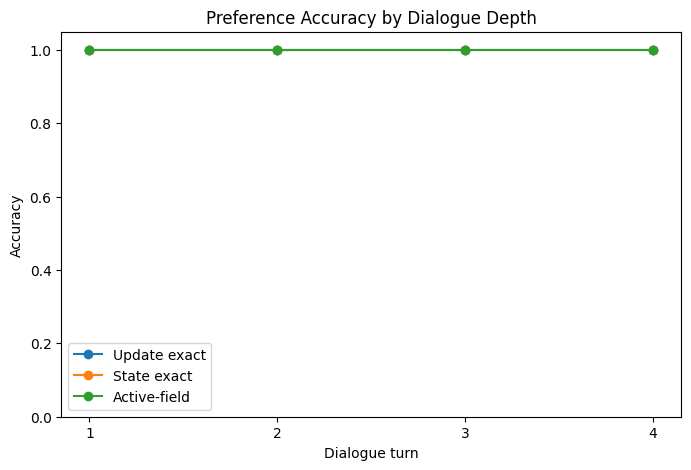

In [16]:

by_depth = (
    results_df
    .groupby("turn", as_index=False)
    .agg(
        turns=("message", "count"),
        update_exact_accuracy=("update_exact_match", "mean"),
        state_exact_accuracy=("state_exact_match", "mean"),
        active_field_accuracy=("active_field_accuracy", "mean"),
        clarification_accuracy=("clarification_accuracy", "mean"),
        mean_latency_s=("latency_s", "mean"),
    )
)

display(by_depth)

plt.figure(figsize=(8, 5))
plt.plot(by_depth["turn"], by_depth["update_exact_accuracy"], marker="o", label="Update exact")
plt.plot(by_depth["turn"], by_depth["state_exact_accuracy"], marker="o", label="State exact")
plt.plot(by_depth["turn"], by_depth["active_field_accuracy"], marker="o", label="Active-field")
plt.ylim(0, 1.05)
plt.xticks(by_depth["turn"])
plt.xlabel("Dialogue turn")
plt.ylabel("Accuracy")
plt.title("Preference Accuracy by Dialogue Depth")
plt.legend()
plt.show()


## 12. Accuracy by scenario type

In [17]:

by_scenario = (
    results_df
    .groupby("scenario_type", as_index=False)
    .agg(
        turns=("message", "count"),
        update_exact_accuracy=("update_exact_match", "mean"),
        state_exact_accuracy=("state_exact_match", "mean"),
        active_field_accuracy=("active_field_accuracy", "mean"),
        clarification_accuracy=("clarification_accuracy", "mean"),
        mean_latency_s=("latency_s", "mean"),
    )
    .sort_values(["state_exact_accuracy", "update_exact_accuracy", "scenario_type"])
)

display(by_scenario)


,scenario_type,turns,update_exact_accuracy,state_exact_accuracy,active_field_accuracy,clarification_accuracy,mean_latency_s
0,ambiguity,1,1.0,1.0,1.0,1.0,1.594875
1,ambiguity_resolution,2,1.0,1.0,1.0,1.0,1.813329
2,colloquial_numeric,5,1.0,1.0,1.0,1.0,1.363351
3,contradictory_same_turn,2,1.0,1.0,1.0,1.0,1.543775
4,correction,5,1.0,1.0,1.0,1.0,1.476594
5,cross_turn_reference,4,1.0,1.0,1.0,1.0,1.506497
6,cross_turn_retention,2,1.0,1.0,1.0,1.0,1.455070
7,multi_attribute,7,1.0,1.0,1.0,1.0,1.629927
8,no_op,5,1.0,1.0,1.0,1.0,1.302603
9,removal,4,1.0,1.0,1.0,1.0,1.729874



## 13. Failure inspection

The important v2 output is not just the aggregate score. It is the exact list of failure turns and whether the error came from extraction, clarification, or propagated state.


In [18]:

if not all_failures:
    print("No failures found in this run.")
else:
    for i, failure in enumerate(all_failures, start=1):
        print("=" * 110)
        print(f"FAILURE {i}")
        print(failure["dialogue_name"], "| turn", failure["turn"], "|", failure["scenario_type"])
        print("Message:", failure["message"])
        print("\nPredicted update:")
        print(json.dumps(failure["predicted_update"], indent=2, ensure_ascii=False))
        print("\nOracle update:")
        print(json.dumps(failure["oracle_update"], indent=2, ensure_ascii=False))
        print("\nPredicted state:")
        print(json.dumps(failure["predicted_state"], indent=2, ensure_ascii=False))
        print("\nExpected state:")
        print(json.dumps(failure["expected_state"], indent=2, ensure_ascii=False))
        print()


No failures found in this run.


## 14. Export results

In [19]:

results_df.to_csv("adversarial_mvp_v2_turn_results.csv", index=False)
by_depth.to_csv("adversarial_mvp_v2_by_depth.csv", index=False)
by_scenario.to_csv("adversarial_mvp_v2_by_scenario.csv", index=False)

print("Saved:")
print("- adversarial_mvp_v2_turn_results.csv")
print("- adversarial_mvp_v2_by_depth.csv")
print("- adversarial_mvp_v2_by_scenario.csv")


Saved:
- adversarial_mvp_v2_turn_results.csv
- adversarial_mvp_v2_by_depth.csv
- adversarial_mvp_v2_by_scenario.csv



## 15. Optional grounded response-generation check

This remains secondary. The response model sees only the validated preference state and selected product records.


In [20]:

RESPONSE_INSTRUCTIONS = """
You are the final product-discovery response generator.

Generate a concise user-facing response using ONLY the supplied validated preference state and product records.

Rules:
1. Do not invent product facts.
2. Every factual product claim must be directly supported by the supplied product records.
3. Do not claim battery life, build quality, benchmark performance, availability, discounts, or other facts unless present in the records.
4. Briefly relate shown products to the active user constraints.
5. If no products are supplied, state that no current catalogue products satisfy all active constraints.
6. Do not claim that a product is objectively the best.
"""

def generate_grounded_response(state, representatives):
    if representatives.empty:
        return "No current catalogue products satisfy all active constraints."

    if not USE_OPENAI:
        lines = ["Qualified representative products:"]
        for _, r in representatives.iterrows():
            lines.append(
                f"- {r['title']}: AUD ${r['price']}, {r['ram_gb']} GB RAM, "
                f"{r['storage_gb']} GB storage, {r['screen_in']}-inch display, GPU: {r['gpu']}."
            )
        return "\n".join(lines)

    records = representatives.to_dict(orient="records")
    response = client.responses.create(
        model=MODEL,
        instructions=RESPONSE_INSTRUCTIONS,
        input=f"""
VALIDATED PREFERENCE STATE:
{json.dumps(state, indent=2)}

SUPPLIED PRODUCT RECORDS:
{json.dumps(records, indent=2)}
""".strip()
    )
    return response.output_text

response_audit_rows = []

if RUN_RESPONSE_GENERATION:
    for output in final_outputs[:MAX_RESPONSE_DEMOS]:
        response_text = generate_grounded_response(output["final_state"], output["representatives"])

        response_audit_rows.append({
            "dialogue_name": output["dialogue_name"],
            "final_state": json.dumps(output["final_state"]),
            "source_products": json.dumps(output["representatives"].to_dict(orient="records")),
            "generated_response": response_text,
            "faithful_yes_no": "",
            "unsupported_claims": "",
            "notes": "",
        })

        print("=" * 110)
        print(output["dialogue_name"])
        print("\nSOURCE RECORDS")
        print(json.dumps(output["representatives"].to_dict(orient="records"), indent=2))
        print("\nGENERATED RESPONSE")
        print(response_text)
        print()

    response_audit_df = pd.DataFrame(response_audit_rows)
    display(response_audit_df)
    response_audit_df.to_csv("adversarial_mvp_v2_response_faithfulness_audit.csv", index=False)
    print("Saved: adversarial_mvp_v2_response_faithfulness_audit.csv")
else:
    print("RUN_RESPONSE_GENERATION=False; skipped.")


D01 — accumulation and explicit correction

SOURCE RECORDS
[
  {
    "product_id": "L01",
    "title": "Dell Inspiron 14 Plus",
    "brand": "Dell",
    "price": 1399,
    "ram_gb": 32,
    "storage_gb": 1024,
    "screen_in": 14.0,
    "gpu": "INTEL ARC",
    "usage_tags": [
      "study",
      "business",
      "general"
    ]
  },
  {
    "product_id": "L02",
    "title": "Lenovo IdeaPad Pro 14",
    "brand": "Lenovo",
    "price": 1499,
    "ram_gb": 32,
    "storage_gb": 1024,
    "screen_in": 14.0,
    "gpu": "INTEGRATED",
    "usage_tags": [
      "study",
      "business",
      "general"
    ]
  }
]

GENERATED RESPONSE
Both options meet your study needs, 32GB RAM minimum, 512GB+ storage requirement, and $1,500 budget:

- **Dell Inspiron 14 Plus** — **$1,399**; 32GB RAM, 1TB storage, 14-inch display, Intel Arc graphics. Tagged for study, business, and general use.
- **Lenovo IdeaPad Pro 14** — **$1,499**; 32GB RAM, 1TB storage, 14-inch display, integrated graphics. Tagged for 

,dialogue_name,final_state,source_products,generated_response,faithful_yes_no,unsupported_claims,notes
0,D01 — accumulation and explicit correction,"{""budget_max"": 1500.0, ""brand"": null, ""ram_min...","[{""product_id"": ""L01"", ""title"": ""Dell Inspiron...","Both options meet your study needs, 32GB RAM m...",,,
1,D02 — removal with retained context,"{""budget_max"": 2000.0, ""brand"": null, ""ram_min...","[{""product_id"": ""L05"", ""title"": ""Acer Swift Go...",These business-suitable laptops match your act...,,,
2,D03 — gaming and budget overwrite,"{""budget_max"": 2000.0, ""brand"": null, ""ram_min...","[{""product_id"": ""L12"", ""title"": ""Acer Nitro V ...",These gaming laptops meet your active requirem...,,,
3,D04 — colloquial money and memory,"{""budget_max"": 1500.0, ""brand"": null, ""ram_min...","[{""product_id"": ""L01"", ""title"": ""Dell Inspiron...",Two catalogue options meet your study-focused ...,,,
4,D05 — storage conversion and doubling reference,"{""budget_max"": 2500.0, ""brand"": null, ""ram_min...","[{""product_id"": ""L15"", ""title"": ""Lenovo Creato...",Here are two business-suitable options that me...,,,


Saved: adversarial_mvp_v2_response_faithfulness_audit.csv



## 16. Interpretation and next step

A useful adversarial result is **not necessarily 100% accuracy**. The notebook is successful if it reveals where the design is robust and where it fails.

Pay particular attention to:
- correction / overwrite
- removal
- contextual references
- ambiguity
- unsupported schema requests
- later-turn error propagation

### GPU requirement

No GPU is required for this architecture as currently defined:
- the LLM is accessed through an external API;
- validation/state management are normal Python logic;
- candidate retrieval is deterministic structured filtering;
- evaluation is lightweight CPU work.

A GPU would become relevant only if the project later chose to host a local language model, run local embedding inference, or introduce a learned retrieval model. Those are optional extensions, not required by this MVP.

### After v2

If the adversarial behaviour is acceptable:

1. Freeze the canonical laptop schema.
2. Replace the synthetic catalogue with cleaned Amazon Reviews 2023 laptop metadata.
3. Refactor notebook code into Python modules.
4. Add unit/integration tests.
5. Wrap the component in FastAPI.
6. Containerise it.
7. Move the stable service into the AWS MLOps workflow.
